# K-Nearest Neighbours (KNN)

One of the two baseline models from the paper (Section IV-A, originally from Kachavimath et al. [4]).

KNN stores the training rows. To classify a new connection it finds the *k* closest training rows (Euclidean distance) and takes a majority vote. Distances are dominated by large-valued features, so features are standardised first. Defined in `src/dosdetect/models.py` as `knn()`; default k = 5.

In [1]:
import pandas as pd

from dosdetect.data import prepare_all
from dosdetect.evaluate import evaluate, evaluate_all, metrics_table, paper_table, plot_confusions
from dosdetect.models import MODELS

pd.set_option("display.precision", 4)

## Data

Normal and DoS traffic only (`dosdetect.data.prepare_all`). Six setups, three splits at two feature counts:

- **official**: NSL-KDD, train on `KDDTrain+`, test on `KDDTest+`. A share of the test DoS rows are attack types never seen in training (apache2, mailbomb, processtable, udpstorm); the count is printed below.
- **holdout**: NSL-KDD, stratified 80/20 split of `KDDTrain+`, so every test attack type was also seen in training.
- **kddcup**: KDDCup'99 (10% file), stratified 80/20 split. The labelled KDDCup test file is no longer downloadable, so there is no official split for this dataset.
- **8 features** (top 8 by |Spearman correlation| with the label, our reading of the paper's filter) or **all 41**. On KDDCup this ranking reproduces the features the paper names (`dst_bytes`, `protocol_type`, the connection counts); on NSL-KDD it does not (see the README). The table below shows the NSL-KDD top 8.

In [2]:
data = prepare_all()
official = data[("official", 8)]
print("Train rows:", len(official["X_train"]), " Test rows:", len(official["X_test"]))
print(
    "Unseen DoS rows in official test:",
    official["unseen"].sum(),
    "of",
    int(official["y_test"].sum()),
    "DoS rows",
)
official["prep"].correlations.head(8).rename("|correlation| with label").to_frame()

Train rows: 113270  Test rows: 17169
Unseen DoS rows in official test: 1717 of 7458 DoS rows


,|correlation| with label
same_srv_rate,0.8433
flag,0.7974
diff_srv_rate,0.7747
serror_rate,0.7712
srv_serror_rate,0.7686
dst_host_serror_rate,0.7485
dst_host_srv_serror_rate,0.7410
count,0.7366


## Results

`recall_unseen` is the share of never-seen DoS attack types the model still catches (official split only).

In [3]:
results = evaluate_all(MODELS["knn"], data)
metrics_table(results)

,accuracy,precision,recall,f1,recall_seen,recall_unseen,train_time_s,predict_time_s
"official, 8 features",0.8666,0.9309,0.7483,0.8297,0.8767,0.3192,0.0258,1.7516
"official, 41 features",0.8953,0.9900,0.7667,0.8641,0.9753,0.0693,0.0647,1.8375
"holdout, 8 features",0.9733,0.9908,0.9428,0.9662,NaN,NaN,0.0089,1.2735
"holdout, 41 features",0.9996,0.9996,0.9993,0.9995,NaN,NaN,0.0368,1.8211
"kddcup, 8 features",0.9988,0.9993,0.9992,0.9992,NaN,NaN,0.0311,25.3758
"kddcup, 41 features",0.9999,0.9999,1.0000,1.0000,NaN,NaN,0.1447,28.4516


### Compared with the paper

The paper reports one result per model, taken from [4] and measured across KDDCup **and** NSL-KDD ("across the two datasets"), with an unstated split and a different 8-feature set. We have no way to reproduce [4]'s split, so the table below takes our two 8-feature setups that are closest in spirit: NSL-KDD with the official train/test files and KDDCup with our 80/20 split. `mean` is the plain average of the two columns, the like-for-like counterpart of a single "across the two datasets" figure, and `difference` is `mean` minus the paper. The two columns differ a lot, so the mean hides most of the story: read the per-dataset columns first.

In [4]:
paper_table("knn", results)

,NSL-KDD,KDDCup,mean,paper [4],difference
accuracy,0.8666,0.9988,0.9327,0.9851,-0.0524
precision,0.9309,0.9993,0.9651,0.9890,-0.0239
recall,0.7483,0.9992,0.8738,0.9780,-0.1042


### Confusion matrices

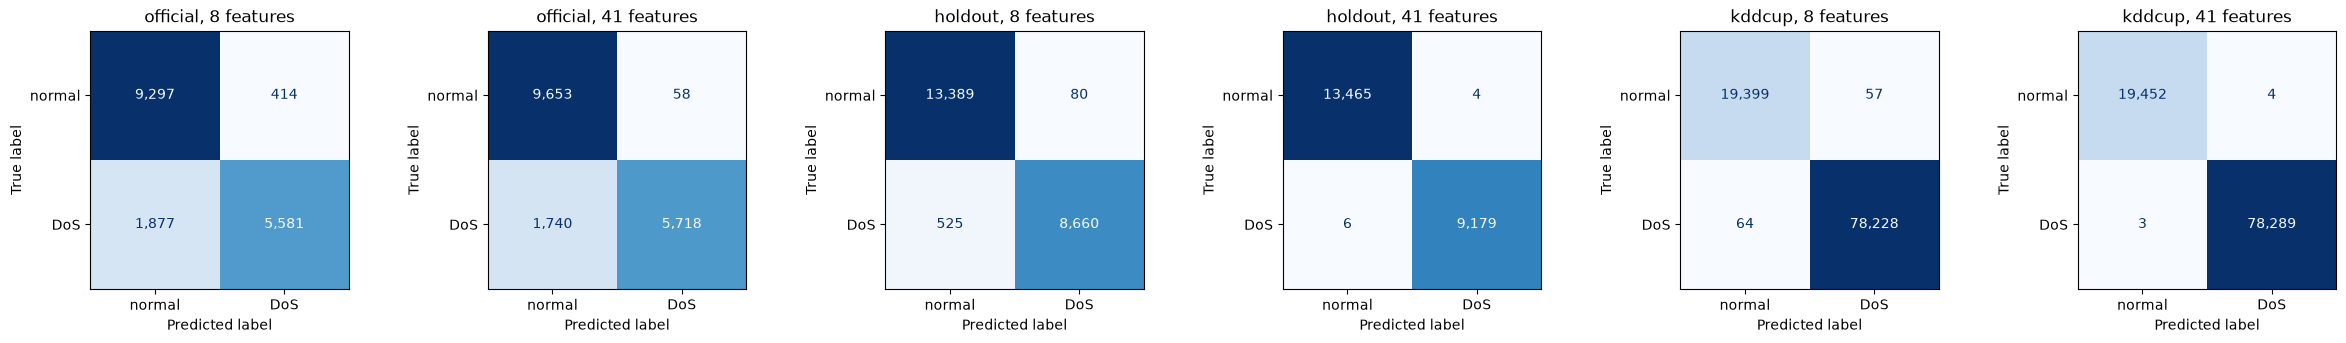

In [5]:
plot_confusions(results);

## Choosing k

Small k follows the training data closely; large k smooths the decision. Official split, 8 features.

In [6]:
ks = [1, 3, 5, 7, 9, 15, 25]
sweep = {f"k={k}": evaluate(MODELS["knn"](k=k), official) for k in ks}
k_table = metrics_table(sweep)[["accuracy", "precision", "recall", "f1", "recall_unseen"]]
k_table

,accuracy,precision,recall,f1,recall_unseen
k=1,0.8609,0.9167,0.7477,0.8236,0.3238
k=3,0.8675,0.9291,0.7523,0.8314,0.3326
k=5,0.8666,0.9309,0.7483,0.8297,0.3192
k=7,0.8659,0.9305,0.7471,0.8288,0.3186
k=9,0.8660,0.9316,0.7464,0.8288,0.3162
k=15,0.8666,0.9324,0.7471,0.8295,0.3151
k=25,0.8666,0.9330,0.7466,0.8294,0.3232


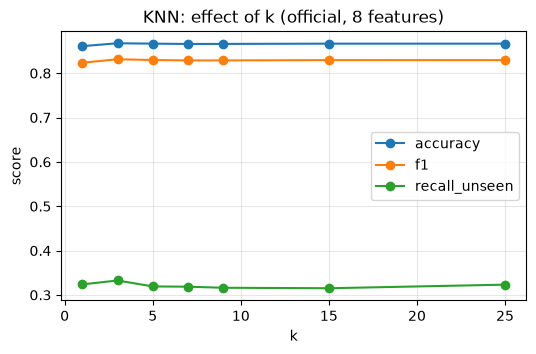

In [7]:
ax = k_table[["accuracy", "f1", "recall_unseen"]].set_axis(ks).plot(marker="o", figsize=(6, 3.5))
ax.set(xlabel="k", ylabel="score", title="KNN: effect of k (official, 8 features)")
ax.grid(alpha=0.3)

## Prediction cost

Ratio of prediction time to KNN's, on the 8-feature setups, measured in this run (the ratio is machine-independent enough to compare; the absolute time is not).

In [8]:
speed = {}
for model in ("naive_bayes", "decision_tree"):
    other = evaluate_all(MODELS[model], {k: v for k, v in data.items() if k[1] == 8})
    speed[model] = {
        split: results[(split, 8)]["predict_time_s"] / other[(split, 8)]["predict_time_s"]
        for split in ("official", "holdout", "kddcup")
    }
pd.DataFrame(speed).round(0).rename_axis("KNN predict time / model's")

,naive_bayes,decision_tree
KNN predict time / model's,,
official,1545.0,1237.0
holdout,1058.0,773.0
kddcup,7322.0,9611.0


## Takeaways

- **Far from the paper on NSL-KDD, close on KDDCup.** With 8 features KNN reaches 99.9% accuracy and 99.9% recall on our KDDCup split, but only 86.7% accuracy and 74.8% recall on the official NSL-KDD test file. The two-dataset mean is 93.3% accuracy and 87.4% recall against the paper's 98.5% and 97.8% (comparison table), so the mean is 5.2 points low on accuracy and 10.4 points low on recall, and the gap comes entirely from NSL-KDD.
- **Unseen attack types are the problem.** On the official split KNN catches 87.7% of DoS rows of attack types it saw in training but only 31.9% of new ones (1717 of the 7458 official-test DoS rows are of unseen types). With 41 features, seen recall rises to 97.5% while unseen recall falls to 6.9%: more features let it match known attacks more tightly, and new ones look less like any of them.
- **k barely matters.** On the official split, k from 1 to 25 moves accuracy only between 86.1% and 86.8%, and recall between 74.6% and 75.2%, so changing k cannot close the gap to the paper or fix the unseen-attack gap.
- **Slowest to predict, by orders of magnitude.** KNN compares every test row to every training row. In the prediction-cost table its predict time is hundreds to a thousand-odd times that of Naive Bayes and the decision tree on the two NSL-KDD splits, and several times more again on KDDCup, whose training set is larger. Exact ratios vary from run to run and with the machine.